# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Patrick Lee, Jason Zermani, Tesher Baer, Nathan Brence

**Date:** 11/11/2026

         sale_price  house_square_feet      bedrooms     bathrooms  \
count  1.679700e+04       16797.000000  16797.000000  16797.000000   
mean   4.609776e+05        1880.764363      3.280169      2.318390   
std    2.342215e+05         759.762716      0.888038      0.826711   
min    2.000000e+03           1.000000      0.000000      0.000000   
25%    3.480000e+05        1320.000000      3.000000      2.000000   
50%    4.163430e+05        1774.000000      3.000000      2.000000   
75%    5.235450e+05        2352.000000      4.000000      3.000000   
max    6.130000e+06        9510.000000     25.000000      8.000000   

            stories    year_built    fireplaces  
count  16797.000000  16797.000000  16797.000000  
mean       1.559028   1980.469012      0.889445  
std        0.511287     33.337722      0.596574  
min        0.000000   1880.000000      0.000000  
25%        1.000000   1959.000000      1.000000  
50%        2.000000   1990.000000      1.000000  
75%        2.000000

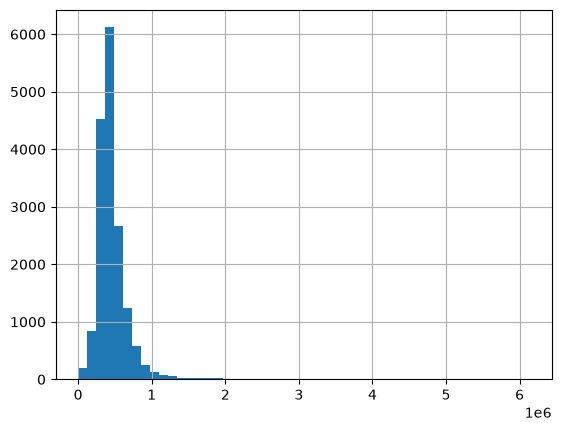

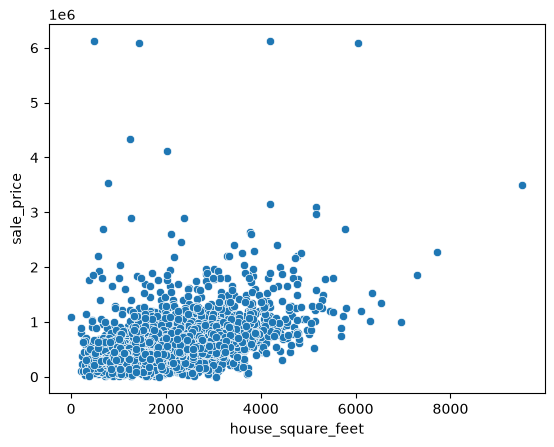

In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/pierce_county_house_sales.csv")

numeric = ["house_square_feet", "bedrooms", "bathrooms", "stories", "year_built", "fireplaces"]
# the waterfront_type and view_quality columns are not considered, since they contain mostly null entries
categorical = ["exterior", "interior", "hvac_description", "roof_cover", "utility_sewer"]
features = numeric + categorical

df = df.dropna(subset=features + ["sale_price"]).copy()
df = df[df["sale_price"] > 0]

print(df[["sale_price"] + numeric].describe())
print(df["exterior"].value_counts())

df["sale_price"].hist(bins=50)
plt.show()

sns.scatterplot(data=df, x="house_square_feet", y="sale_price")
plt.show()

In [2]:
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df["sale_price"]

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# model 1: Use all numeric and categorical variables
model_1 = LinearRegression().fit(X_train, y_train)

train_pred = model_1.predict(X_train)
test_pred = model_1.predict(X_test)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

# model 2: Use only numeric features
X2=df[numeric]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=100)

model_2 = LinearRegression().fit(X2_train, y2_train)

train2_pred = model_2.predict(X2_train)
test2_pred = model_2.predict(X2_test)

train2_r2 = r2_score(y2_train, train2_pred)
test2_r2 = r2_score(y2_test, test2_pred)

# model 3: Use only categorical variables 
X3 = pd.get_dummies(df[categorical], drop_first=True, dtype=int)
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.20, random_state=100)

model_3 = LinearRegression().fit(X3_train, y3_train)

train3_pred = model_3.predict(X3_train)
test3_pred = model_3.predict(X3_test)

train3_r2 = r2_score(y3_train, train3_pred)
test3_r2 = r2_score(y3_test, test3_pred)

R2_df = pd.DataFrame({"Model 1": [train_r2, test_r2],
           "Model 2": [train2_r2, test2_r2],
           "Model 3": [train3_r2, test3_r2]}, index=["Train R2", "Test R2"])

R2_df

,Model 1,Model 2,Model 3
Train R2,0.366792,0.325131,0.156204
Test R2,0.450976,0.443152,0.164941


The R2 values of each model indicates that Model 1, which has the highest train and test R2, does the best out of the three. 

In [5]:
from statsmodels.graphics.regressionplots import plot_partregress_grid
import statsmodels.api as sm

partial_data = df[["sale_price", "house_square_feet", "bedrooms", "bathrooms"]].copy()

model = sm.OLS(partial_data["sale_price"], sm.add_constant(partial_data[["house_square_feet", "bedrooms", "bathrooms"]])).fit()

fig = plt.figure(figsize=(12, 8))
plot_partregress_grid(model, fig=fig)
plt.tight_layout()
plt.show()



ModuleNotFoundError: No module named 'statsmodels'

Plots don't show any strong non-linearities. There are some outliers, but the relationships between the different variables and sale price are generally linear.

In [ ]:
#question 6
df_complex = df.copy()

#nonlinear transformations
df_complex["sqft_squared"] = df_complex["house_square_feet"] ** 2
df_complex["log_sqft"] = np.log1p(df_complex["house_square_feet"])

#interaction terms
df_complex["bed_bath"] = (
    df_complex["bedrooms"] * df_complex["bathrooms"]
)

df_complex["sqft_bath"] = (
    df_complex["house_square_feet"] * df_complex["bathrooms"]
)

# grouping
common_exteriors = ["Frame Siding", "Frame Vinyl",
                    "Masonry Common Brick", "Frame Stucco"]

df_complex["exterior_grouped"] = df_complex["exterior"].where(
    df_complex["exterior"].isin(common_exteriors),
    "Other"
)
df_complex = pd.get_dummies(
    df_complex,
    columns=["exterior_grouped"],
    drop_first=True,
    dtype=int
)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

features = [
    "house_square_feet",
    "bedrooms",
    "bathrooms",
    "sqft_squared",
    "log_sqft",
    "bed_bath",
    "sqft_bath"
]

#add exterior_grouped columns to the features list
features += [
    col for col in df_complex.columns
    if col.startswith("exterior_grouped_")
]

X = df_complex[features]
y = df_complex["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, train_pred)))

print("Testing RMSE:",
      np.sqrt(mean_squared_error(y_test, test_pred)))

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, test_pred))

Training RMSE: 191632.50562787437
Testing RMSE: 183363.7316311164
Training R²: 0.33967328097197924
Testing R²: 0.35128945524901634


The model that included interactions and transformed variables had a lower train and test R-Squared than the best-performing simple linear model from question 4, indicating that the addition of interactions and transformations had a negative effect on the model's predictive power.

Question 7: The results show that Model 1 performed the best overall, with a training R^2 of 0.367 and a testing R^2 of 0.451. The complex model performed slightly worse, with a training R^2 of 0.342 and a testing R^2 of 0.340. Adding more variables and changes to the regression model did not make it more accurate at predicting house prices. A model that is too simple can underfit the data, and on the other hand a model that is too complex can overfit by capturing patterns that are not applicable to new data. The complex model did not improve performance, so the simpler Model 1 is the optimal choice.

In [ ]:
from sklearn.linear_model import Lasso

lasso = Lasso()
lasso.fit(X_train, y_train)

train_pred = lasso.predict(X_train)
test_pred = lasso.predict(X_test)

print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, train_pred)))

print("Testing RMSE:",
      np.sqrt(mean_squared_error(y_test, test_pred)))

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, test_pred))

lasso_features = [features[i] for i in range(len(features)) if lasso.coef_[i] != 0]
print(f"Selected Lasso Features: {pd.DataFrame(lasso_features)}")


Training RMSE: 191632.50656948585
Testing RMSE: 183364.19653421486
Training R²: 0.3396732744827753
Testing R²: 0.3512861657443592
Selected Lasso Features:                                         0
0                       house_square_feet
1                                bedrooms
2                               bathrooms
3                            sqft_squared
4                                log_sqft
5                                bed_bath
6                               sqft_bath
7           exterior_grouped_Frame Stucco
8            exterior_grouped_Frame Vinyl
9   exterior_grouped_Masonry Common Brick
10                 exterior_grouped_Other


c:\Users\nafer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.467e+14, tolerance: 7.473e+10
  model = cd_fast.enet_coordinate_descent(


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]